Progetto  Freshness & Waste Explorer

Obiettivo di questo notebook : Rispondere con i dati a 5 ipotesi di business formulate nel file 'README'

**Le 5 ipotesi:**
1. Le categorie deperibili (Butchers, Food, Milk Products, Patisserie) generano una quota di fatturato
   proporzionalmente maggiore nel weekend rispetto alle categorie non deperibili.
2. Esiste una stagionalita' mensile riconoscibile nelle vendite di prodotti deperibili.
3. Il valore medio dello scontrino (`Total Spent`) e' piu' alto quando viene applicato uno sconto.
4. Alcuni giorni della settimana concentrano una quota sproporzionata delle transazioni sui prodotti
   deperibili (i "giorni critici" per la gestione del riordino).
5. Il pagamento in contanti e' associato a scontrini di importo mediamente piu' basso rispetto a carta/wallet.


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [106]:
#Importo il mio file csv pulito 
df = pd.read_csv('df_cleaning.csv')

In [107]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Year,Month,Day_name
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True,2024,4,Monday
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True,2023,7,Sunday
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False,2022,10,Wednesday
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,False,2022,5,Saturday
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False,2022,10,Sunday


In [108]:
df.shape

(12575, 14)

In [109]:
#verifica ulteriore di presenza di valori nulli
df.isnull().sum()

Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
Year                0
Month               0
Day_name            0
dtype: int64

# Analisi EDA

## Pnoramica generale

In [110]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Year', 'Month', 'Day_name'],
      dtype='str')

In [111]:
#elemmnti presenti in category
df['Category'].unique().tolist()

['Patisserie',
 'Milk Products',
 'Butchers',
 'Beverages',
 'Food',
 'Furniture',
 'Electric household essentials',
 'Computers and electric accessories']

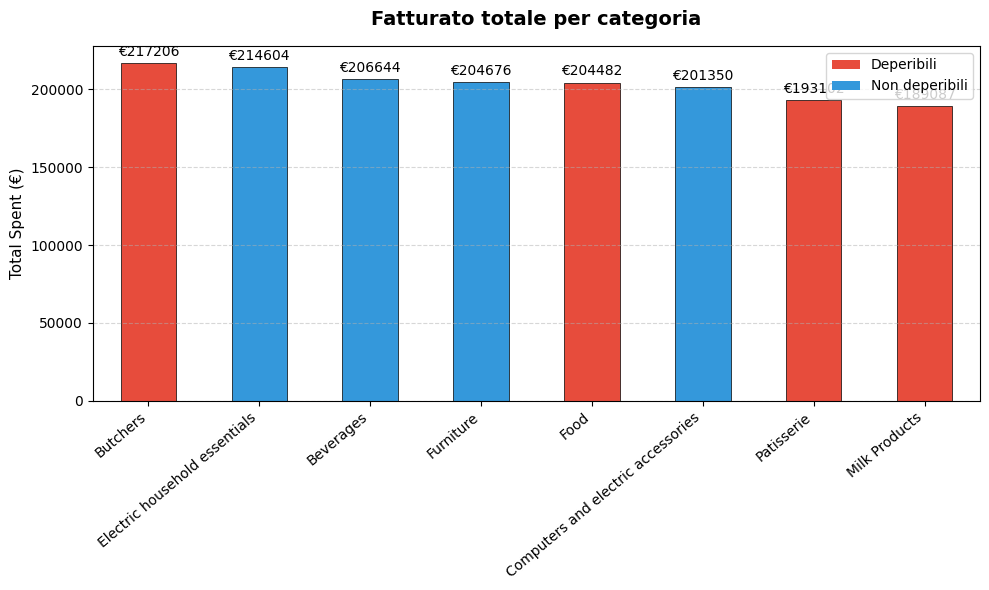

In [112]:
#Vediamo la distribuzione del fatturato per categoria

revenue_category= df.groupby('Category')['Total Spent'].sum().sort_values(ascending=False)

#Categorie deperibili
PERISHABLE_CATEGORIES = ["Butchers", "Food", "Milk Products", "Patisserie"]

#Creo una lista per i colori per ogni barra

colors= [
    '#e74c3c' if cat in PERISHABLE_CATEGORIES else '#3498db' 
    for cat in revenue_category.index]

fig, ax =plt.subplots(figsize=(10,6))
bars= revenue_category.plot(kind='bar',
                            ax=ax,
                            color=colors,
                            edgecolor='black',
                            linewidth= 0.5)

ax.set_title('Fatturato totale per categoria',fontsize=14,pad=15,fontweight='bold')
ax.set_ylabel('Total Spent (€)',fontsize=11)
ax.set_xlabel("")
ax.grid(axis='y', linestyle='--', alpha=0.5)

#Aggiungo una leggenda 
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='Deperibili'),
    Patch(facecolor='#3498db', label='Non deperibili')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.xticks(rotation=40, ha="right", fontsize=10)
ax.bar_label(bars.containers[0], fmt='€%.0f', padding=3)
plt.tight_layout()
plt.savefig('Fatturato totale per categoria.png', dpi=300, bbox_inches='tight')
plt.show()

**NOTE** = Possiamo notare come il fatturato totale composto dalla vendita di categorie molto omogenee . Non c'è una catogoria di prodotto che vende più delle altre . Possiamo notare come la categoria 'Butchers' sia quella con il maggior fatturato 

###  **IPOTESI 1: Deperibili e Weekend** :


##### Le categorie deperibili (Butchers, Food, Milk Products, Patisserie) generano una quota di fatturato proporzionalmente maggiore nel weekend rispetto alle categorie non deperibili?
   

In [113]:
PERISHABLE_CATEGORIES = ["Butchers", "Food", "Milk Products", "Patisserie"]
NON_PERISHABLE_CATEGORIES=['Beverages','Furniture','Electric household essentials','Computers and electric accessories']

#Definisco le condizioni
condition = [df['Category'].isin(PERISHABLE_CATEGORIES),
             df['Category'].isin(NON_PERISHABLE_CATEGORIES)]

#Definisco le etichette
labels= ['Deperibile','Non Deperibile']

#Creo la nuova colonna
df['Tipo_prodotto']= np.select(condition,labels,default='Altro')




In [114]:
Weekend = ['Saturday', 'Sunday']


# Crea la tabella pivot
df_pivot = df.pivot_table(
    index='Tipo_prodotto', 
    columns='Day_name', 
    values='Total Spent', 
    aggfunc='sum',
    fill_value=0,
)

#Identifico i giorni festivi presenti nel dataFrame
col_festivi= [g for g in Weekend if g in df_pivot.columns]
df_weekend = df_pivot[col_festivi].copy()

#calcolo il totale del weekend per i deperibili e non deperibili 
df_weekend["Total_weekend"] = df_weekend.sum(axis=1)
print(df_weekend)


Day_name        Saturday    Sunday  Total_weekend
Tipo_prodotto                                    
Deperibile      116056.5  112998.0       229054.5
Non Deperibile  119386.0  122608.0       241994.0


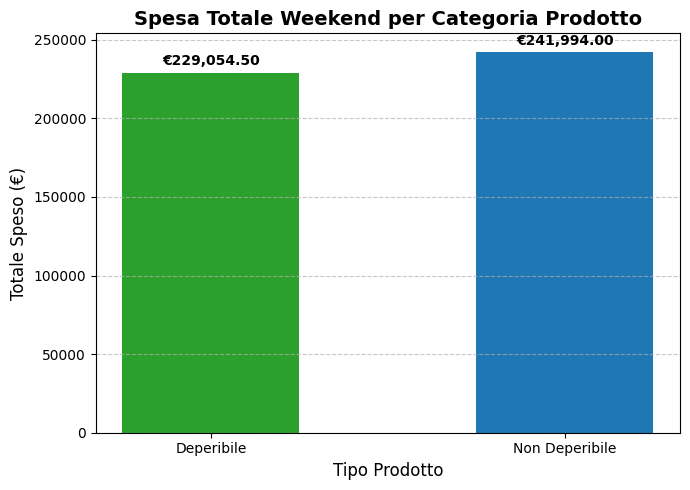

In [115]:
#Grafico a barre 
plt.figure(figsize=(7, 5))
bars = plt.bar(
    df_weekend.index,
    df_weekend["Total_weekend"],
    color=["#2ca02c", "#1f77b4", "#7f7f7f"],
    width=0.5,
)

plt.title(
    "Spesa Totale Weekend per Categoria Prodotto",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Tipo Prodotto", fontsize=12)
plt.ylabel("Totale Speso (€)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Etichette sui valori delle barre
for i, v in enumerate(df_weekend["Total_weekend"]):
    plt.text(i, v + (v * 0.02), f"€{v:,.2f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig('Spesa Totale Weekend per Categoria Prodotto.png', dpi=300, bbox_inches='tight')
plt.show()


**Considerazioni** : Possiamo notare come nel weekend il fatturato dei prodotti deperibili è motlo alto , ma non superiore ai prodotti non deperibili . Posiamo notare come le vendite dei prodotti deperibili e non deperibili nel weekend è molto simile , non c'è una delle due categorie che vende di più . Quindi le categorie deperibili (Butchers, Food, Milk Products, Patisserie) non  generano una quota di fatturato proporzionalmente maggiore nel weekend rispetto alle categorie non deperibili

###  **IPOTESI 2: Stagionalità prodotti deperibili** :

##### Esiste una stagionalita' mensile riconoscibile nelle vendite di prodotti deperibili?

In [116]:
# Dizionario dei mesi
maps_month = {
    1: 'Gennaio', 2: 'Febbraio', 3: 'Marzo', 4: 'Aprile',
    5: 'Maggio', 6: 'Giugno', 7: 'Luglio', 8: 'Agosto',
    9: 'Settembre', 10: 'Ottobre', 11: 'Novembre', 12: 'Dicembre'
}

# Mappatura e ordinamento dei mesi
df['Name_Month'] = df['Month'].map(maps_month)
df['Name_Month'] = pd.Categorical(df['Name_Month'], 
                                  categories=list(maps_month.values()), 
                                  ordered=True)

# Filtraggio dei prodotti deperibili
df_deperibili = df[df['Tipo_prodotto'] == 'Deperibile'] 

#Aggregazione per mese (formato adatto al grafico)
df_trend = (
    df_deperibili.groupby('Name_Month', observed=False)['Total Spent']
    .sum()
    .reset_index()
)

#Media delle vendite dei prodotti deperibili
media_vendite= df_trend['Total Spent'].mean()

print ('Stagionalità dei prodotti deperibili:')
print(df_trend)
print('La media delle vendite dei prodotti deperibili è :', 
-media_vendite)


Stagionalità dei prodotti deperibili:
   Name_Month  Total Spent
0     Gennaio     88447.50
1    Febbraio     61227.00
2       Marzo     64630.25
3      Aprile     60109.00
4      Maggio     65541.00
5      Giugno     63951.50
6      Luglio     68272.00
7      Agosto     62491.00
8   Settembre     67236.00
9     Ottobre     69761.00
10   Novembre     65195.50
11   Dicembre     67015.00
La media delle vendite dei prodotti deperibili è : -66989.72916666667


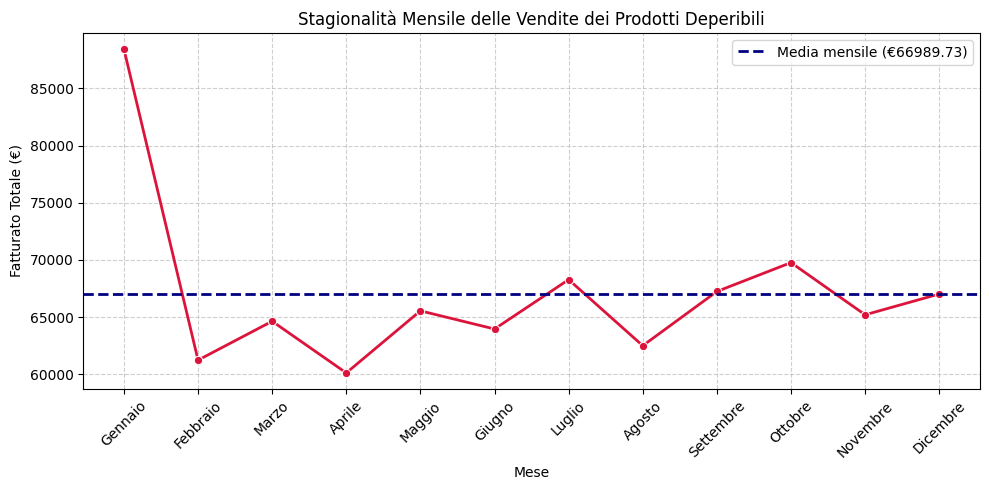

In [117]:
# Visualizzazione grafica del trend mensile
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_trend,
    x='Name_Month',
    y='Total Spent',
    marker='o',
    color='crimson',
    linewidth=2,
)

#Visualizzazione grafica della media 
plt.axhline(
    y=media_vendite,
    color='navy',
    linestyle='--',
    linewidth=2,
    label=f'Media mensile (€{media_vendite:.2f})',
)

plt.title(
    'Stagionalità Mensile delle Vendite dei Prodotti Deperibili', fontsize=12
)
plt.xlabel('Mese')
plt.ylabel('Fatturato Totale (€)')
plt.xticks(rotation=45) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('Stagionalità Mensile delle Vendite dei Prodotti Deperibili.png', dpi=300, bbox_inches='tight')
plt.show()

**Considerazioni**:L'analisi delle vendite evidenzia una marcata stagionalità per la categoria dei prodotti deperibili. Si osserva un primo forte picco di fatturato a Gennaio (massimo assoluto dell'anno), seguito da una ripresa della domanda nei mesi estivi e autunnali — in particolare a Luglio, Settembre ed Ottobre — per poi chiudere con un nuovo incremento a Dicembre in concomitanza con le festività. Tutti questi mesi registrano performance costantemente superiori alla media annuale, suggerendo una forte correlazione tra la domanda di beni deperibili e specifici periodi dell'anno o ricorrenze di consumo.



###  **IPOTESI 3: Media scontrino Vs Sconto applicato** :

##### Il valore medio dello scontrino (`Total Spent`) e' piu' alto quando viene applicato uno sconto.

In [118]:
# Calcolo del valore medio dello scontrino 
media_scontrino_con_sconto = df[df['Discount Applied']== True]['Total Spent'].mean()
media_scontrino_senza_sconto = df[df['Discount Applied']== False]['Total Spent'].mean()

#Condizioni:
if media_scontrino_con_sconto > media_scontrino_senza_sconto :
    print('Si, il valore medio dello scontrino è più alto quando viene applicato uno sconto ')
else:
    print('NO, il valore medio dello scontrino non è più alto quando viene applicato uno sconto ')


print(f"Media scontrino CON sconto: €{media_scontrino_con_sconto:.2f}")
print(f"Media scontrino SENZA sconto: €{media_scontrino_senza_sconto:.2f}")

Si, il valore medio dello scontrino è più alto quando viene applicato uno sconto 
Media scontrino CON sconto: €130.49
Media scontrino SENZA sconto: €129.32


**Considerazioni**: Dall'analisi effettuata possiamo notare come il valore medio dello scontrino è più alto quando viene applicato uno sconto e più basso quando non viene applicato nessuno sconto 

###  **IPOTESI 4: I "giorni critici" per la gestione del riordino** :

##### Alcuni giorni della settimana concentrano una quota sproporzionata delle transazioni sui prodotti deperibili (i "giorni critici" per la gestione del riordino).

In [119]:
df_deperibili = df[df['Tipo_prodotto'] == 'Deperibile']
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
giorni_critici= df_deperibili.groupby('Day_name')['Total Spent'].sum().reindex(order, fill_value=0)

# Calcolo dei 2 giorni top e della relativa quota sul totale
top_2_giorni = giorni_critici.sort_values(ascending=False).head(2)
top_share = top_2_giorni.sum() / giorni_critici.sum()

print(giorni_critici)
print('------------------------------------------------')
print(top_2_giorni)

Day_name
Monday       104287.00
Tuesday      121952.25
Wednesday    114923.25
Thursday     111024.00
Friday       122635.75
Saturday     116056.50
Sunday       112998.00
Name: Total Spent, dtype: float64
------------------------------------------------
Day_name
Friday     122635.75
Tuesday    121952.25
Name: Total Spent, dtype: float64


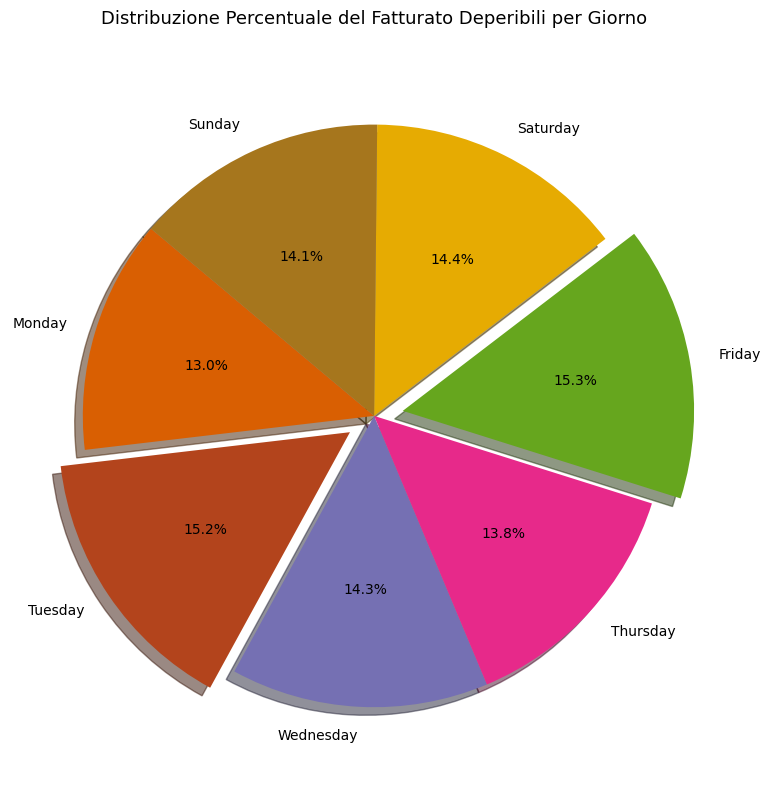

In [120]:
explode = [
    0.10 if giorno in top_2_giorni.index else 0
    for giorno in giorni_critici.index
]

# Palette di colori personalizzata
palette_colori = [
    '#d95f02',
    '#b3441c',
    '#7570b3',
    '#e7298a',
    '#66a61e',
    '#e6ab02',
    '#a6761d',
]

# 5. Generazione del Grafico a Torta
fig, ax = plt.subplots(figsize=(8, 8))

giorni_critici.plot(
    kind='pie',
    ax=ax,
    autopct='%1.1f%%',
    startangle=140,
    explode=explode,
    colors=palette_colori,
    shadow=True,
    textprops={'fontsize': 10},
)

ax.set_title(
    'Distribuzione Percentuale del Fatturato Deperibili per Giorno',
    fontsize=13,
    pad=20,
)
ax.set_ylabel('')  

plt.tight_layout()
plt.savefig('Distribuzione Percentuale del Fatturato Deperibili per Giorno.png', dpi=300, bbox_inches='tight')
plt.show()

**Considerazioni**:
* Distribuzione omogenea: A differenza delle aspettative di una forte concentrazione nel fine settimana, il fatturato dei prodotti deperibili mostra un andamento molto bilanciato lungo tutto l'arco della settimana.   
* Giorni di picco: I due giorni più forti risultano essere Venerdì e Martedì, i quali concentrano complessivamente il 30,4% del fatturato settimanale della categoria.   

* Confutazione dell'ipotesi: Non si evidenzia una quota "sproporzionata" nei giorni critici, poiché il valore del 30,4% sui due giorni migliori è molto vicino a una distribuzione teorica perfettamente uniforme (circa 28,6%).
* Implicazioni gestionali: L'assenza di marcati picchi o crolli indica una domanda costante. Di conseguenza, la logistica di riordino e rifornimento dei prodotti deperibili deve prevedere flussi continui e giornalieri anziché massimizzare le scorte solo in vista del weekend, garantendo così la massima freschezza dei prodotti ed evitando sprechi.

###  **IPOTESI 5: Contanti o Carta/Wallet** :

#####  Il pagamento in contanti e' associato a scontrini di importo mediamente piu' basso rispetto a carta/wallet?

In [121]:
contanti = df[df['Payment Method'] == 'Cash']['Total Spent'].mean()
carta_wallet = df[df['Payment Method'].isin(['Digital Wallet', 'Credit Card'])]['Total Spent'].mean()

if contanti < carta_wallet:
    print(
        "Sì, il pagamento in contanti è associato a scontrini di importo mediamente PIÙ BASSO rispetto a carta/wallet."
    )
elif contanti > carta_wallet:
    print(
        "No, il pagamento in contanti è associato a scontrini di importo mediamente PIÙ ALTO rispetto a carta/wallet."
    )
else:
    print(
        "Il valore medio dello scontrino è IDENTICO tra contanti e carta/wallet.")

print(f"Media scontrino Contanti: €{contanti:.2f}")
print(f"Media scontrino Carte/Wallet: €{carta_wallet:.2f}")

No, il pagamento in contanti è associato a scontrini di importo mediamente PIÙ ALTO rispetto a carta/wallet.
Media scontrino Contanti: €131.08
Media scontrino Carte/Wallet: €129.00


**Considerazioni:**
L'ipotesi iniziale viene confutata dai dati. I pagamenti effettuati in contanti registrano uno scontrino medio leggermente superiore (€131,08) rispetto a quelli saldati tramite carte o wallet digitali (€129,00).
La differenza contenuta (circa €2,08) evidenzia come la scelta del metodo di pagamento non influisca negativamente sulla propensione di spesa del cliente, smentendo l'idea che l'uso del contante sia rilegato a sole transazioni di piccolo importo.

## **Riepilogo finale:**

#### Sintesi delle 5 ipotesi

| # | Ipotesi | Esito |
|---|---|---|
| 1 | Deperibili pesano di piu' nel weekend | *smentita*  |
| 2 | Stagionalita' mensile sui deperibili | *confermata* |
| 3 | Sconto associato a scontrino piu' alto | *confermata* |
| 4 | Giorni critici concentrano il fatturato deperibile | *smentita* |
| 5 | Pagamento in contanti = scontrino piu' basso | *smentita* |



